# Faz 2 — Veri temizleme ve ön işleme

Bu notebook vize kriteri **5**'i (veri kalitesi sorunlarının belirlenmesi, temizleme/dönüştürme yöntemleri,
öncesi–sonrası karşılaştırma) karşılar.

**Girdi:** Faz 1 çıktıları (`veri/islenmis/cagrilar_eslesmis.parquet`, `fiyat_pencereleri.parquet`) ve MAEC metinleri.
Önce `01_veri_edinme_eslestirme.ipynb` çalıştırılmış olmalı.
**Çıktı:** `veri/islenmis/temiz_cagrilar.parquet` (temiz metin + etiket), `veri/islenmis/seri_girdisi.npz`
(60 × 3 fiyat girdisi), `sekiller/f2_*.png`, `cikti/f2_*.csv`. Süre ~1 dk.

In [1]:
import re
import sys
import textwrap
from pathlib import Path

KOK = Path.cwd().resolve().parent
sys.path.insert(0, str(KOK))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from src import etiket, temizle, veri

SEKIL, CIKTI, ISLENMIS = KOK / "sekiller", KOK / "cikti", KOK / "veri" / "islenmis"
SINIF_RENK = ["#6da7ec", "#2a78d6", "#104281"]
MAVI, TURUNCU, GRI, KOYU = "#2a78d6", "#eb6834", "#9a9893", "#3a3a38"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.facecolor": "white", "axes.titlesize": 11})
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)


def kaydet(fig, ad):
    fig.savefig(SEKIL / f"{ad}.png", bbox_inches="tight")


def tr(x, nd=0):
    """Sayıyı Türkçe yazar: binlik nokta, ondalık virgül."""
    return f"{x:,.{nd}f}".replace(",", "§").replace(".", ",").replace("§", ".")


VIRGUL = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ","))

tablo = pd.read_parquet(ISLENMIS / "cagrilar_eslesmis.parquet").set_index("klasor")
pencere = pd.read_parquet(ISLENMIS / "fiyat_pencereleri.parquet")
cumleler = veri.maec_oku().set_index("klasor").loc[tablo.index, "cumleler"]
print("Faz 1'den gelen eşleşmiş çağrı:", len(tablo), "| fiyat penceresi satırı:", len(pencere))

Faz 1'den gelen eşleşmiş çağrı: 3026 | fiyat penceresi satırı: 217872


## 1. Veri kalitesi sorunlarının envanteri (Kriter 5)

Her sorun ölçülür, sonra bir karar verilir. Faz 1'de ele alınanlar da bütünlük için tabloda yer alır.

In [2]:
metin_ham = [" ".join(s) for s in cumleler]
kelime_ham = tablo.n_kelime
g_girdi = pencere[pencere.gun.between(-60, -1)]
g_hedef = pencere[pencere.gun.between(0, 6)]
sifir_hedef = g_hedef.groupby("klasor").getiri.apply(lambda s: int((s == 0).sum()))
sifir_girdi = g_girdi.groupby("klasor").getiri.apply(lambda s: (s == 0).mean())
ayni_metin = pd.Series(metin_ham).duplicated(keep=False)
cumle_uzunluk = np.array([len(x.split()) for s in cumleler for x in s])
kalip = temizle.kalip_say(metin_ham)

envanter = pd.DataFrame([
    ("Eksik veri", "fiyat", "ticker'ı FNSPID'de olmayan çağrı", "411", "Faz 1'de çıkarıldı"),
    ("Bozuk dosya", "fiyat", "kesik dosya (SON, SAFM tek satır; SPN, SJI geç başlıyor)", "6 çağrı", "Faz 1'de çıkarıldı"),
    ("Eksik veri", "fiyat", "girdi/hedef penceresinde eksik gün ya da getiri", "0", "işlem gerekmez"),
    ("Eksik veri", "metin", f"içeriksiz metin (≤ {temizle.MIN_KELIME} kelime)", f"{int((kelime_ham <= temizle.MIN_KELIME).sum())} çağrı", "çıkarılır (Bölüm 2)"),
    ("Tekrar kayıt", "metin", "birebir aynı metin", f"{int(ayni_metin.sum())} çağrı (hepsi \"Thank you.\")", "içeriksiz metin kuralıyla çıkar"),
    ("Tekrar kayıt", "metin", "aynı şirketin çağrı çiftlerinde en yüksek cümle benzerliği (Jaccard)", "0,158 (Faz 1)", "kopya yok; işlem gerekmez"),
    ("Kalite düşüklüğü", "metin", "dökümcü notu ([indiscernible], (ph) …)", f"{kalip['dökümcü notu ([indiscernible], (ph) …)']['toplam']}", "silinir (Bölüm 3)"),
    ("Kalite düşüklüğü", "metin", "köşeli parantezli ekleme ([million] …)", f"{kalip['köşeli parantezli ekleme ([million] …)']['toplam']}", "parantez kaldırılır, içerik kalır"),
    ("Kalite düşüklüğü", "metin", "<UNK> (gizlenmiş kişi adı)", f"{kalip['<UNK> (gizlenmiş kişi adı)']['toplam']}", "[NAME] olarak tekilleştirilir"),
    ("Kalite düşüklüğü", "metin", "tipografik karakter / HTML varlığı / URL",
     f"{kalip['tipografik karakter (’ – … •)']['toplam']} / {kalip['HTML varlığı (&amp; …)']['toplam']} / {kalip['URL']['toplam']}", "düz karşılığa çevrilir / [URL]"),
    ("Aykırı değer", "metin", "çok uzun \"cümle\" (cümle bölme hatası)", f"en uzun {cumle_uzunluk.max()} kelime (%99: {int(np.percentile(cumle_uzunluk, 99))})", "korunur; model cümle sınırına dayanmıyor"),
    ("Aykırı değer", "fiyat", "|günlük log getiri| > 0,4 (girdi + hedef)", f"{int((pencere[pencere.gun.between(-60, 6)].getiri.abs() > 0.4).sum())} gün", "gerçek hareket (düzeltilmemiş kapanışta da aynı); korunur"),
    ("Kalite düşüklüğü", "fiyat", "hedef penceresinde ≥ 3 gün sıfır getiri", f"{int((sifir_hedef >= 3).sum())} çağrı", "işlem hacmi var; gerçek (Bölüm 4)"),
    ("Kalite düşüklüğü", "fiyat", "girdi penceresinin > %10'u sıfır getiri", f"{int((sifir_girdi > 0.1).sum())} çağrı", "işlem hacmi var; gerçek (Bölüm 4)"),
    ("Kalite düşüklüğü", "fiyat", "yüksek < düşük, kapanış aralık dışında, hacim 0/NaN",
     f"{int((g_girdi.high < g_girdi.low).sum() + (g_girdi.close > g_girdi.high * 1.0001).sum() + (g_girdi.close < g_girdi.low * 0.9999).sum() + (g_girdi.volume <= 0).sum() + g_girdi.volume.isna().sum())}", "işlem gerekmez"),
    ("Etiket sorunu", "etiket", "bir eşiğe 0,10 log biriminden yakın", "673 çağrı (%22,2; Faz 1)", "korunur; belirsizlik raporlanır"),
    ("Etiket sorunu", "etiket", "çağrı saati yok (BMO/AMC karışık)", "|r0| > |r+1|: %56,5 (Faz 1)", "hedef gün 0..+6 (kural C)"),
], columns=["tür", "modalite", "sorun", "ölçüm", "karar"])
envanter.to_csv(CIKTI / "f2_kalite_envanteri.csv", index=False)
envanter

,tür,modalite,sorun,ölçüm,karar
0,Eksik veri,fiyat,ticker'ı FNSPID'de olmayan çağrı,411,Faz 1'de çıkarıldı
1,Bozuk dosya,fiyat,"kesik dosya (SON, SAFM tek satır; SPN, SJI geç başlıyor)",6 çağrı,Faz 1'de çıkarıldı
2,Eksik veri,fiyat,girdi/hedef penceresinde eksik gün ya da getiri,0,işlem gerekmez
3,Eksik veri,metin,içeriksiz metin (≤ 20 kelime),26 çağrı,çıkarılır (Bölüm 2)
4,Tekrar kayıt,metin,birebir aynı metin,"17 çağrı (hepsi ""Thank you."")",içeriksiz metin kuralıyla çıkar
5,Tekrar kayıt,metin,aynı şirketin çağrı çiftlerinde en yüksek cümle benzerliği (Jaccard),"0,158 (Faz 1)",kopya yok; işlem gerekmez
6,Kalite düşüklüğü,metin,"dökümcü notu ([indiscernible], (ph) …)",1136,silinir (Bölüm 3)
7,Kalite düşüklüğü,metin,köşeli parantezli ekleme ([million] …),1867,"parantez kaldırılır, içerik kalır"
8,Kalite düşüklüğü,metin,<UNK> (gizlenmiş kişi adı),29465,[NAME] olarak tekilleştirilir
9,Kalite düşüklüğü,metin,tipografik karakter / HTML varlığı / URL,4503 / 1 / 161,düz karşılığa çevrilir / [URL]


**Ne gözlendi:** Fiyat tarafındaki sorunların çoğu Faz 1'de ele alındı (eksik ticker, kesik dosya); eşleşen çağrılarda eksik gün, tutarsız yüksek/düşük fiyat ya da sıfır hacim yok. Metin tarafında sorunlar biçimsel: 29.465 gizlenmiş ad, 1.136 dökümcü notu, 1.867 köşeli parantezli ekleme, 4.503 tipografik karakter, 161 URL. Birebir aynı 17 metin gerçek tekrar değil; hepsi yalnız "Thank you." içeren, hizalaması başarısız kayıtlar.

**Neden önemli:** Hoca kriteri sorunların araştırılıp sayısallaştırılmasını istiyor; her satır bir ölçüm ve bir kararla eşleşiyor. Aykırı görünen bazı değerler (|getiri| > 0,4, sıfır getirili günler) incelendiğinde gerçek piyasa davranışı çıkıyor; bunları "temizlemek" veriyi bozardı.

**Sonraki aşamaya etkisi:** Bölüm 2–5'te kararlar uygulanıyor ve en az iki öncesi–sonrası karşılaştırmayla gösteriliyor.

## 2. Öncesi–sonrası 1: içeriksiz metinlerin çıkarılması

**Yöntem:** Kelime sayısı ≤ 20 olan metinler çıkarılır. **Gerekçe:** Bu aralıktaki metinler incelendiğinde hepsi
selamlaşma ya da kapanış cümlesi (aşağıdaki örnekler); çağrının içeriğine dair bilgi taşımıyor. 21–100 kelimelik
metinlerde ise gerçek içerik görülüyor (ör. "$3 million to $5 million"), bu yüzden eşik daha yükseğe çekilmedi.

In [3]:
kisa = tablo[tablo.n_kelime <= temizle.MIN_KELIME].sort_values("n_kelime")
print(f"≤ {temizle.MIN_KELIME} kelimelik metin: {len(kisa)} çağrı. Örnekler:")
for k in list(kisa.index[:3]) + list(kisa.index[-4:]):
    print(f"  {k} ({kisa.n_kelime[k]} kelime): {textwrap.shorten(' '.join(cumleler[k]), 110)}")
orta = tablo[(tablo.n_kelime > temizle.MIN_KELIME) & (tablo.n_kelime <= 100)].sort_values("n_kelime")
print(f"\nKarşılaştırma için 21–100 kelimelik metin: {len(orta)} çağrı. Örnekler:")
for k in orta.index[[0, len(orta) // 2, -1]]:
    print(f"  {k} ({orta.n_kelime[k]} kelime): {textwrap.shorten(' '.join(cumleler[k]), 110)}")

≤ 20 kelimelik metin: 26 çağrı. Örnekler:
  20150506_NSIT (2 kelime): Thank you.
  20151105_HE (2 kelime): Thank you.
  20150819_LZB (2 kelime): Thank you.
  20151125_DE (10 kelime): And then was proposed by our actuarial company, so --
  20151028_GRMN (11 kelime): Thank you. Thanks, everyone, for attending today. Appreciate it. Take care.
  20151110_ZBRA (16 kelime): Thank you. Thank you. And thank you, everyone, for joining us today. That concludes our call.
  20150504_FN (17 kelime): Thank you, everybody, for joining us today. We look forward to talking to you in the future.

Karşılaştırma için 21–100 kelimelik metin: 57 çağrı. Örnekler:
  20160802_CMI (21 kelime): Thank you. Thanks, <UNK>. Thank you very much, everybody. I will be available for any follow-ups, if you [...]
  20161027_QEP (46 kelime): Thank you. Thank you, Audrey. Thanks, everyone, for dialing in today. We appreciate your interest in QEP [...]
  20170202_ELY (98 kelime): <UNK>, I don't have the December share in fro

,önce,sonra,çıkan,önce %,sonra %
sinif,,,,,
düşük,1081,1068,13,35.72,35.6
orta,948,939,9,31.33,31.3
yüksek,997,993,4,32.95,33.1
toplam,3026,3000,26,100.00,100.0


Çıkan çağrı: 26 (%0.86) | sınıf paylarındaki en büyük değişim: 0.15 yüzde puan


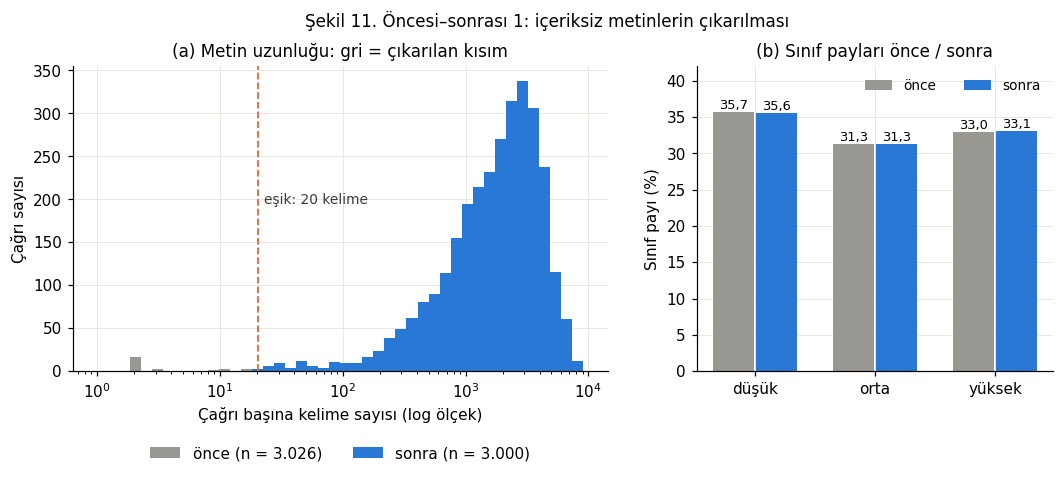

In [4]:
tut = tablo.n_kelime > temizle.MIN_KELIME
once = tablo.sinif.value_counts().sort_index()
sonra = tablo[tut].sinif.value_counts().sort_index()
kiyas = pd.DataFrame({"önce": once, "sonra": sonra, "çıkan": once - sonra}).rename(index=dict(enumerate(etiket.SINIF_ADLARI)))
kiyas["önce %"] = (100 * kiyas["önce"] / kiyas["önce"].sum()).round(2)
kiyas["sonra %"] = (100 * kiyas["sonra"] / kiyas["sonra"].sum()).round(2)
kiyas.loc["toplam"] = [once.sum(), sonra.sum(), once.sum() - sonra.sum(), 100, 100]
display(kiyas)
print(f"Çıkan çağrı: {int((~tut).sum())} (%{100 * (~tut).mean():.2f}) | sınıf paylarındaki en büyük değişim: "
      f"{(kiyas['sonra %'] - kiyas['önce %']).iloc[:3].abs().max():.2f} yüzde puan")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
kutular = np.logspace(0, np.log10(tablo.n_kelime.max() + 1), 45)
a1.hist(tablo.n_kelime.clip(lower=1), bins=kutular, color=GRI, label=f"önce (n = {tr(len(tablo))})")
a1.hist(tablo[tut].n_kelime, bins=kutular, color=MAVI, label=f"sonra (n = {tr(tut.sum())})")
a1.axvline(temizle.MIN_KELIME + 0.5, color=TURUNCU, lw=1.2, ls="--")
a1.text(temizle.MIN_KELIME * 1.15, a1.get_ylim()[1] * 0.55, f"eşik: {temizle.MIN_KELIME} kelime", fontsize=9, color=KOYU)
a1.set_xscale("log")
a1.set_xlabel("Çağrı başına kelime sayısı (log ölçek)")
a1.set_ylabel("Çağrı sayısı")
a1.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
a1.set_title("(a) Metin uzunluğu: gri = çıkarılan kısım")
x = np.arange(3)
for j, (kol, renk) in enumerate([("önce %", GRI), ("sonra %", MAVI)]):
    a2.bar(x + (j - 0.5) * 0.36, kiyas[kol].iloc[:3], width=0.34, color=renk, label=kol.replace(" %", ""))
    for xi, p in zip(x, kiyas[kol].iloc[:3]):
        a2.text(xi + (j - 0.5) * 0.36, p + 0.4, tr(p, 1), ha="center", fontsize=8.5)
a2.set_xticks(x, etiket.SINIF_ADLARI)
a2.set_ylabel("Sınıf payı (%)")
a2.set_ylim(0, 42)
a2.legend(frameon=False, fontsize=9, loc="upper right", ncol=2)
a2.set_title("(b) Sınıf payları önce / sonra")
fig.suptitle("Şekil 11. Öncesi–sonrası 1: içeriksiz metinlerin çıkarılması", y=1.02, fontsize=11)
kaydet(fig, "f2_01_icerksiz_metin")
plt.show()

**Ne gözlendi:** 26 çağrı (%0,86) çıkarıldı: 13 düşük, 9 orta, 4 yüksek sınıftan. Sınıf paylarındaki en büyük değişim 0,15 yüzde puan. Çıkan metinlerin tamamı selamlaşma, kapanış ya da anlamsız parça (ör. 10 kelimelik "And then was proposed by our actuarial company, so --").

**Neden önemli:** Bu çağrılarda metin modalitesi fiilen yok; modele boş metin vermek, metnin katkısını ölçerken gürültü yaratırdı. Kayıp küçük ve sınıf dengesini bozmuyor.

**Sonraki aşamaya etkisi:** Nihai veri 3.000 çağrı. Bilgi kaybı: 26 çağrının fiyat serisi de kullanılmıyor; finalde eksik metinli çağrılarla tek-modalite (yalnız fiyat) dayanıklılık denemesi istenirse bu kayıtlar `cagrilar_eslesmis.parquet` içinde duruyor.

## 3. Öncesi–sonrası 2: metin gürültüsünün temizlenmesi

**Yöntem (`src/temizle.py`, cümle cümle):**
1. HTML varlıkları (`&amp;`) ve tipografik karakterler (’ – … •) düz karşılığına çevrilir.
2. Dökümcü notları (`[indiscernible]`, `[ph]`, `(inaudible)`, `[laughter]` …) silinir: konuşmacının söylediği bir şey değil, yazıya dökenin notu.
3. Köşeli parantezli eklemelerde (`[million]`) parantez kaldırılır, içerik kalır: dökümcünün anlamı netleştirmek için eklediği kelimedir.
4. URL'ler `[URL]`, MAEC'in gizlediği kişi adları (`<UNK>`) `[NAME]` olarak tek biçime getirilir.
5. Fazla boşluklar tekilleştirilir; temizlik sonrası boş kalan cümle atılır.

**Bilerek yapılmayanlar:** Küçük harfe çevirme, noktalama ve durak kelime silme, kök bulma. Bu adımlar kullanılacak
modele göre değişir (ör. TF-IDF'te sözlük aşamasında yapılır, önceden eğitilmiş transformer modellerinde hiç
yapılmaz); veri aşamasında yapılırsa geri alınamaz bilgi kaybı olur. Konuşmadaki duraksamaları gösteren `--` de korunur.

In [5]:
temiz = {k: temizle.metin_temizle(cumleler[k]) for k in tablo.index[tut]}
metin_once = [" ".join(cumleler[k]) for k in temiz]
metin_sonra = [" ".join(s) for s in temiz.values()]
k_once, k_sonra = temizle.kalip_say(metin_once), temizle.kalip_say(metin_sonra)
gurultu = pd.DataFrame({"önce (metin)": {a: v["metin"] for a, v in k_once.items()}, "önce (toplam)": {a: v["toplam"] for a, v in k_once.items()},
                        "sonra (toplam)": {a: v["toplam"] for a, v in k_sonra.items()}})
display(gurultu)


def sozluk(metinler):
    return {w for t in metinler for w in re.findall(r"[A-Za-z][A-Za-z'-]*", t.lower())}


kelime_once = sum(len(t.split()) for t in metin_once)
kelime_sonra = sum(len(t.split()) for t in metin_sonra)
s_once, s_sonra = sozluk(metin_once), sozluk(metin_sonra)
cumle_once = sum(len(cumleler[k]) for k in temiz)
cumle_sonra = sum(len(s) for s in temiz.values())
olcu = pd.DataFrame({"önce": [kelime_once, len(s_once), cumle_once, sum(len(t) for t in metin_once)],
                     "sonra": [kelime_sonra, len(s_sonra), cumle_sonra, sum(len(t) for t in metin_sonra)]},
                    index=["toplam kelime", "farklı kelime türü (küçük harf)", "cümle", "karakter"])
olcu["değişim %"] = (100 * (olcu["sonra"] - olcu["önce"]) / olcu["önce"]).round(3)
display(olcu)
print("Temizlikle sözlükten çıkan kelime türlerinden örnekler:", sorted(s_once - s_sonra)[:25])

,önce (metin),önce (toplam),sonra (toplam)
"dökümcü notu ([indiscernible], (ph) …)",636,1136,1
köşeli parantezli ekleme ([million] …),902,1867,6
URL,149,161,0
<UNK> (gizlenmiş kişi adı),2796,29465,0
tipografik karakter (’ – … •),194,4503,0
HTML varlığı (&amp; …),1,1,0


,önce,sonra,değişim %
toplam kelime,6695821,6694347,-0.022
farklı kelime türü (küçük harf),45620,45601,-0.042
cümle,346643,346585,-0.017
karakter,38477126,38485193,0.021


Temizlikle sözlükten çıkan kelime türlerinden örnekler: ['ain', 'alamo-group', 'alexanderbaldwin', 'american-equity', 'annie', 'aren', 'arnott', 'aswater', 'bankatfirst', 'bedbathandbeyond', 'bet-the', 'calwatergroup', 'centralpacificbank', 'couldn', 'criminally', 'dentsplysirona', 'dsystems', 'earningsslidesmarch', 'elpolloloco', 'encorewire', 'ensigngroup', 'fspreit', 'greif', 'hadn', 'hotus']


In [6]:
ornekler = []
for desen in [r"\[indiscernible\]", r"\(ph\)", r"\[(?:million|billion)\]", r"’", r"www\.|https?://"]:
    for k in temiz:
        hit = [s for s in cumleler[k] if re.search(desen, s) and len(s) < 160]
        if hit:
            ornekler.append({"klasor": k, "önce": hit[0], "sonra": temizle.cumle_temizle(hit[0])})
            break
pd.DataFrame(ornekler)

,klasor,önce,sonra
0,20170126_ADS,What that means is free cash flow at the [indiscernible] will be up a little bit year-over-year,What that means is free cash flow at the will be up a little bit year-over-year
1,20150226_GPS,"So as a Company that has $16 [billion], roughly, in revenue, there's a lot of space out there.","So as a Company that has $16 billion, roughly, in revenue, there's a lot of space out there."
2,20170117_CMA,We don’t really look at it that way,We don't really look at it that way
3,20150428_HELE,"<UNK>, I'd like to inform all interested parties that a copy of today's earnings release has been posted on the Comp...","[NAME], I'd like to inform all interested parties that a copy of today's earnings release has been posted on the Com..."


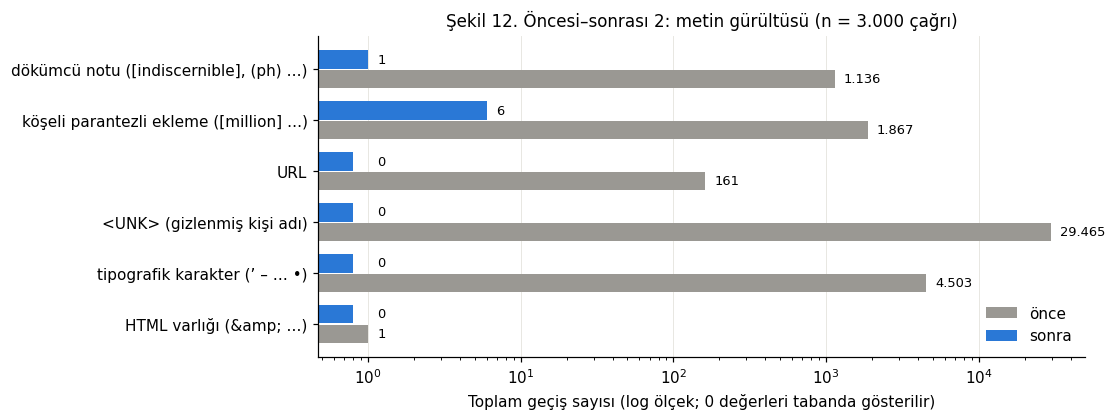

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(gurultu))
ax.barh(y + 0.19, gurultu["önce (toplam)"].clip(lower=0.8), height=0.36, color=GRI, label="önce")
ax.barh(y - 0.19, gurultu["sonra (toplam)"].clip(lower=0.8), height=0.36, color=MAVI, label="sonra")
for yi, (o, s) in enumerate(zip(gurultu["önce (toplam)"], gurultu["sonra (toplam)"])):
    ax.text(max(o, 1) * 1.15, yi + 0.19, tr(o), va="center", fontsize=8.5)
    ax.text(max(s, 1) * 1.15, yi - 0.19, tr(s), va="center", fontsize=8.5)
ax.set_xscale("log")
ax.set_yticks(y, gurultu.index)
ax.invert_yaxis()
ax.set_xlabel("Toplam geçiş sayısı (log ölçek; 0 değerleri tabanda gösterilir)")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
ax.set_title(f"Şekil 12. Öncesi–sonrası 2: metin gürültüsü (n = {tr(len(temiz))} çağrı)")
kaydet(fig, "f2_02_metin_gurultusu")
plt.show()

**Ne gözlendi:** Temizlik sonrası dökümcü notları 1.136'dan 1'e, köşeli parantezli eklemeler 1.867'den 6'ya, URL, gizlenmiş ad ve tipografik karakterler sıfıra indi. Toplam kelime %0,022, farklı kelime türü %0,042, cümle sayısı 58 (%0,017) azaldı. Kalan 1 not ve 6 parantez, MAEC'in cümle bölme hatası yüzünden iki cümleye bölünmüş eklemeler (ör. "[market. ]"); temizlik cümle cümle yapıldığı için yakalanmadı.

**Neden önemli:** Temizlik yalnız konuşma olmayan işaretleri kaldırdı; konuşmanın içeriği neredeyse hiç değişmedi (kelime kaybı binde birin altında). Sözlükten "kaybolan" kelimelerin bir kısmı URL içindeki şirket adları (www.hotus.com), bir kısmı da tipografik kesme işaretinin düzelmesiyle başka biçime geçen kelimeler (Annie’s → Annie's).

**Sonraki aşamaya etkisi:** Metin, model aşamasında seçilecek gösterime (TF-IDF ya da önceden eğitilmiş dil modeli) hazır. Ortanca çağrı yaklaşık 1.900 kelime; 512 parçalık (token) sınırı olan BERT türü modellerde metin parçalara bölünüp birleştirilmeli.

## 4. Sıfır getirili günler: veri hatası mı, gerçek mi?

Faz 1'de bazı çağrılarda kapanış fiyatının günlerce değişmediği görüldü. Fiyat sağlayıcısında donmuş bir kayıt olsaydı
o günlerde işlem hacmi de olmamalıydı. Bu yüzden sıfır getirili günlerdeki hacim ve hissenin fiyat düzeyi incelenir.

In [8]:
supheli = sorted(set(sifir_hedef[sifir_hedef >= 3].index) | set(sifir_girdi[sifir_girdi > 0.1].index))
g = pencere[pencere.gun.between(-60, 6)]
sifir_gun = g[(g.getiri == 0) & g.klasor.isin(supheli)]
fiyat_duzeyi = g.groupby("klasor").close.median()
print(f"Şüpheli çağrı: {len(supheli)} | bu çağrılardaki sıfır getirili gün: {len(sifir_gun)} | "
      f"bunlardan hacmi 0 olan: {int((sifir_gun.volume == 0).sum())} | en düşük hacim: {int(sifir_gun.volume.min()):,}")
print(f"Kapanış fiyatı medyanı: şüpheli çağrılarda {fiyat_duzeyi[supheli].median():.2f} $, tüm çağrılarda {fiyat_duzeyi.median():.2f} $")
sifir_pay = g[g.gun.between(-60, -1)].groupby("klasor").getiri.apply(lambda s: (s == 0).mean())
print(f"Fiyat düzeyi ile sıfır getiri payı arasındaki Spearman korelasyonu: {fiyat_duzeyi.corr(sifir_pay, method='spearman'):.3f}")

Şüpheli çağrı: 29 | bu çağrılardaki sıfır getirili gün: 266 | bunlardan hacmi 0 olan: 0 | en düşük hacim: 6,600
Kapanış fiyatı medyanı: şüpheli çağrılarda 10.56 $, tüm çağrılarda 40.20 $


Fiyat düzeyi ile sıfır getiri payı arasındaki Spearman korelasyonu: -0.392


**Karar:** Sıfır getirili günlerin hepsinde işlem hacmi var ve bu çağrılar düşük fiyatlı hisselere ait; hisse fiyatı
düştükçe en küçük fiyat adımı (1 sent) görece büyür ve kapanışın aynı kalması olağanlaşır. Bu nedenle bu günler veri
hatası sayılmaz, veride bırakılır. Etiket bu çağrılarda düşük çıkabilir, ama bu, hissenin gerçek davranışıdır.

## 5. Öncesi–sonrası 3: fiyat serisinin model girdisine dönüştürülmesi

**Sorun:** Ham seride hisseler arasında ölçek farkı çok büyük (fiyat birkaç dolardan yüzlerce dolara, hacim binlerden
milyonlara). Ayrıca düzeltilmiş kapanışın *düzeyi*, çağrıdan sonra gelen temettü ve bölünmelere göre geriye dönük
değişir; düzeyi modele vermek ileriye dönük bilgi sızıntısı olur.

**Yöntem (`src/temizle.py: seri_girdisi`), yalnız gün −60..−1:**
| Kanal | Tanım | Neden |
|---|---|---|
| getiri | ln(P_t / P_t−1), P = düzeltilmiş kapanış | Ölçekten bağımsız; oynaklığın doğrudan hammaddesi |
| göreli log hacim | ln(hacim_t) − pencerenin ln(hacim) ortalaması | Hisseler arası hacim farkını ve bölünme düzeltmesini siler; yalnız "olağandan fazla/az işlem" kalır |
| günlük aralık | ln(yüksek_t / düşük_t) | Gün içi oynaklık; aynı günün oranı olduğu için düzeltmeden etkilenmez |

Hepsi yalnız girdi penceresindeki günlerden hesaplanır; hedef penceresinden ya da başka çağrılardan bilgi kullanılmaz.
Kanalların ölçeklenmesi (ör. standartlaştırma) Faz 4'te her fold'un yalnız eğitim kısmından öğrenilecek.

In [9]:
X, sira = temizle.seri_girdisi(pencere[pencere.klasor.isin(temiz.keys())])
print("Girdi dizisi:", X.shape, "(çağrı × gün × kanal) | eksik değer:", int(np.isnan(X).sum()))
girdi = pencere[pencere.gun.between(-61, -1) & pencere.klasor.isin(temiz.keys())]
ort_fiyat = girdi.groupby("klasor")["adj close"].mean()
ort_hacim = girdi.groupby("klasor").volume.mean()


def yayilim(s):
    return f"{tr(s.min(), 2)} – {tr(s.max(), 2)} (en büyük / en küçük = {tr(s.max() / s.min())} kat)"


print("ÖNCE  ortalama düzeltilmiş fiyat:", yayilim(ort_fiyat))
print("ÖNCE  ortalama hacim         :", yayilim(ort_hacim))
oz = pd.DataFrame({k: pd.Series(X[:, :, i].ravel()).describe(percentiles=[.01, .5, .99]) for i, k in enumerate(temizle.KANALLAR)}).T
oz.round(4)

Girdi dizisi: (3000, 60, 3) (çağrı × gün × kanal) | eksik değer: 0
ÖNCE  ortalama düzeltilmiş fiyat: 1,98 – 1.869,43 (en büyük / en küçük = 942 kat)
ÖNCE  ortalama hacim         : 26.631,15 – 69.655.350,82 (en büyük / en küçük = 2.616 kat)


,count,mean,std,min,1%,50%,99%,max
getiri,180000.0,0.0005,0.0199,-0.5038,-0.0544,0.0008,0.0513,0.3407
goreli_log_hacim,180000.0,-0.0000,0.4238,-2.4056,-0.9015,-0.0290,1.2419,3.5281
gunluk_aralik,180000.0,0.0252,0.0173,0.0025,0.0066,0.0207,0.0894,0.6950


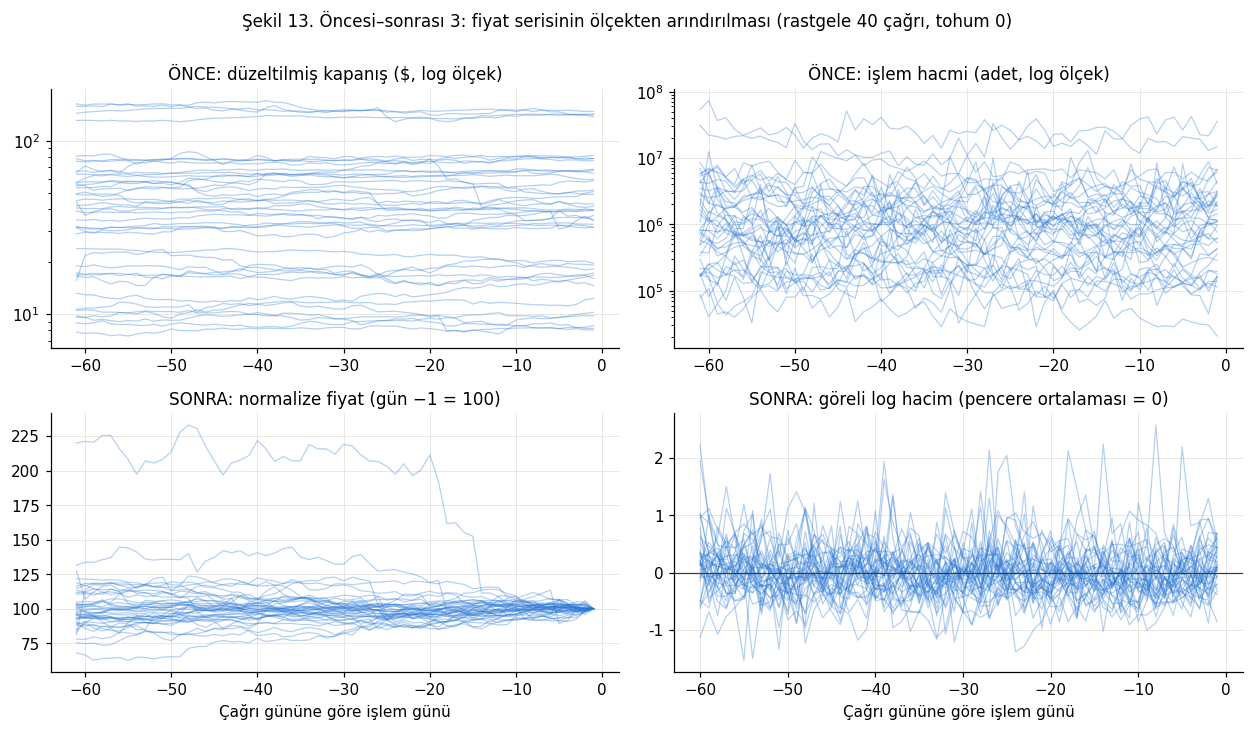

In [10]:
rng = np.random.default_rng(0)
secim = rng.choice(len(sira), 40, replace=False)
fig, eksen = plt.subplots(2, 2, figsize=(11.5, 6.6))
for j in secim:
    p = girdi[girdi.klasor == sira[j]]
    eksen[0, 0].plot(p.gun, p["adj close"], lw=0.8, alpha=0.35, color=MAVI)
    eksen[0, 1].plot(p.gun, p.volume, lw=0.8, alpha=0.35, color=MAVI)
    eksen[1, 0].plot(p.gun, 100 * p["adj close"] / p["adj close"].iloc[-1], lw=0.8, alpha=0.35, color=MAVI)
    eksen[1, 1].plot(range(-60, 0), X[j, :, 1], lw=0.8, alpha=0.35, color=MAVI)
eksen[0, 0].set_yscale("log"); eksen[0, 1].set_yscale("log")
eksen[0, 0].set_title("ÖNCE: düzeltilmiş kapanış ($, log ölçek)")
eksen[0, 1].set_title("ÖNCE: işlem hacmi (adet, log ölçek)")
eksen[1, 0].set_title("SONRA: normalize fiyat (gün −1 = 100)")
eksen[1, 1].set_title("SONRA: göreli log hacim (pencere ortalaması = 0)")
eksen[1, 1].axhline(0, color=KOYU, lw=0.8)
for ax in eksen[1]:
    ax.set_xlabel("Çağrı gününe göre işlem günü")
    ax.yaxis.set_major_formatter(VIRGUL)
fig.suptitle(f"Şekil 13. Öncesi–sonrası 3: fiyat serisinin ölçekten arındırılması (rastgele 40 çağrı, tohum 0)", y=1.0, fontsize=11)
fig.tight_layout()
kaydet(fig, "f2_03_seri_olcek")
plt.show()

**Ne gözlendi:** Ham seride çağrılar arası ortalama fiyat 1,98 $ ile 1.869,43 $ (942 kat), ortalama hacim 26.631 ile 69,7 milyon adet (2.616 kat) arasında değişiyor. Dönüşümden sonra üç kanal da hisseden bağımsız ölçekte: günlük getirinin ortalaması 0,0005 ve std'si 0,0199; göreli log hacmin ortalaması tanım gereği 0, std'si 0,42; günlük aralığın medyanı 0,021. Normalize fiyat yollarının hepsi gün −1'de 100'de buluşuyor.

**Neden önemli:** Ölçek farkı giderilmezse model hisseleri fiyat ya da hacim büyüklüğüyle ayırt eder, oynaklık örüntüsünü öğrenmez. Fiyat düzeyini atmak ayrıca ileriye dönük sızıntıyı engeller. Bilgi kaybı: şirket büyüklüğü ve fiyat düzeyi bilgisi atıldı; gerekirse sızıntısız bir büyüklük göstergesi ayrıca eklenebilir.

**Sonraki aşamaya etkisi:** Uç getiriler (en düşük −0,50, en yüksek +0,34) gerçek hareket olduğu için kırpılmadı; kırpma ya da ölçekleme gerekirse eşikler Faz 4'te yalnız eğitim fold'undan öğrenilecek.

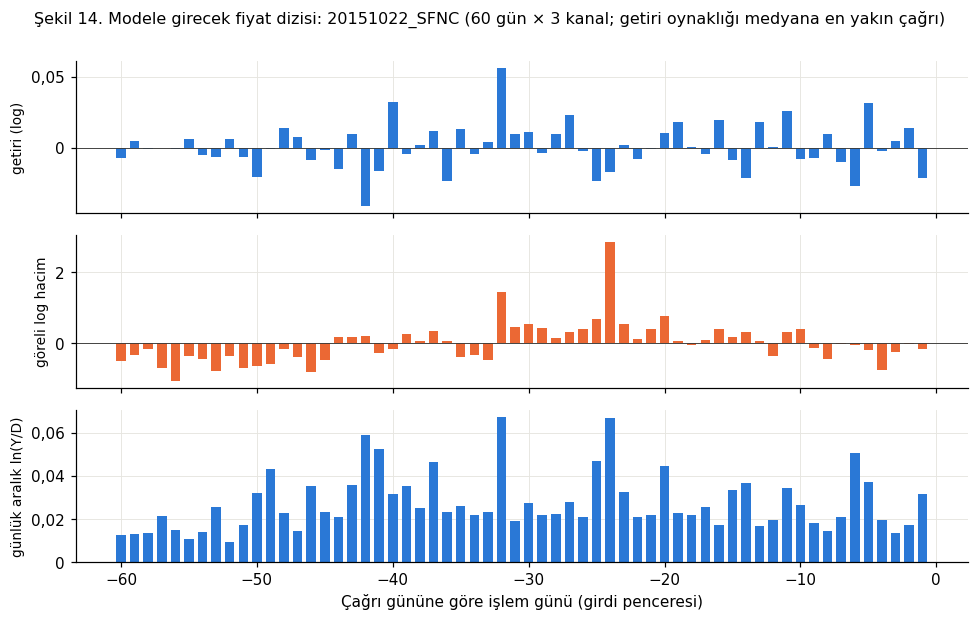

In [11]:
ornek = sira[np.argmin(np.abs(X[:, :, 0].std(axis=1) - np.median(X[:, :, 0].std(axis=1))))]
j = list(sira).index(ornek)
fig, eksen = plt.subplots(3, 1, figsize=(9, 5.6), sharex=True)
adlar = ["getiri (log)", "göreli log hacim", "günlük aralık ln(Y/D)"]
for i, ax in enumerate(eksen):
    ax.bar(range(-60, 0), X[j, :, i], color=MAVI if i != 1 else TURUNCU, width=0.7)
    ax.axhline(0, color=KOYU, lw=0.6)
    ax.set_ylabel(adlar[i], fontsize=9)
    ax.yaxis.set_major_formatter(VIRGUL)
eksen[-1].set_xlabel("Çağrı gününe göre işlem günü (girdi penceresi)")
fig.suptitle(f"Şekil 14. Modele girecek fiyat dizisi: {ornek} (60 gün × 3 kanal; getiri oynaklığı medyana en yakın çağrı)", y=1.0, fontsize=10.5)
fig.tight_layout()
kaydet(fig, "f2_04_seri_kanallari")
plt.show()

**Ne gözlendi:** Her çağrı için model girdisi 60 gün × 3 kanallık bir dizi: getiri, göreli log hacim ve günlük aralık. Örnek çağrıda hacim sıçramaları ile büyük getiri ve geniş aralık günleri aynı günlere denk geliyor.

**Neden önemli:** Bu, fiyat modalitesinin özet sayılar değil gerçek bir zaman serisi olarak modele gireceğini gösteriyor ("metin + metadata" görüntüsü riski). Üç kanal birbirini tamamlıyor: getiri yönü ve büyüklüğü, hacim ilgi düzeyini, aralık gün içi belirsizliği taşıyor.

**Sonraki aşamaya etkisi:** Final aşamasında bu dizi bir zaman serisi kodlayıcısına (1D-CNN ya da LSTM) verilecek; metin ayrı bir kodlayıcıdan geçip ikisi füzyonla birleşecek.

## 6. Temiz veri setinde etiketler ve kayıt

Çağrı çıkarıldığı için eğitim kısmı (≤ 2016) değişti; eşikler temiz eğitim kısmından yeniden hesaplanır ve Faz 1
etiketleriyle karşılaştırılır.

In [12]:
son = tablo[tut].copy()
egitim = (son.tarih <= "2016-12-31").to_numpy()
esik_yeni = etiket.esikler(son.v[egitim])
son["sinif_f1"] = son.sinif
son["sinif"] = etiket.siniflandir(son.v, esik_yeni).astype(int)
print("Eşikler Faz 1:", np.round(etiket.esikler(tablo.v[(tablo.tarih <= '2016-12-31').to_numpy()]), 4), "→ temiz veri:", np.round(esik_yeni, 4))
print("Sınıfı değişen çağrı:", int((son.sinif != son.sinif_f1).sum()))
sinif_son = pd.DataFrame({"tümü": son.sinif.value_counts().sort_index(), "eğitim (≤2016)": son[egitim].sinif.value_counts().sort_index(),
                          "sonrası (2017–2018)": son[~egitim].sinif.value_counts().sort_index()}).rename(index=dict(enumerate(etiket.SINIF_ADLARI)))
sinif_son.loc["toplam"] = sinif_son.sum()
display(sinif_son)

son["cumleler_temiz"] = [temiz[k] for k in son.index]
son["n_kelime_temiz"] = [sum(len(x.split()) for x in temiz[k]) for k in son.index]
son = son.loc[list(sira)]
son.reset_index().to_parquet(ISLENMIS / "temiz_cagrilar.parquet", index=False)
np.savez_compressed(ISLENMIS / "seri_girdisi.npz", X=X.astype("float32"), klasor=np.array(sira), kanallar=np.array(temizle.KANALLAR))
dokum2 = pd.DataFrame([("Faz 1 sonunda eşleşmiş çağrı", len(tablo)), (f"içeriksiz metin (≤ {temizle.MIN_KELIME} kelime) çıkarıldı", -int((~tut).sum())),
                       ("Faz 2 sonunda temiz çağrı", len(son))], columns=["adım", "çağrı"])
dokum2.to_csv(CIKTI / "f2_temizlik_dokumu.csv", index=False)
sinif_son.to_csv(CIKTI / "f2_sinif_dagilimi.csv")
gurultu.to_csv(CIKTI / "f2_metin_gurultusu.csv")
olcu.to_csv(CIKTI / "f2_metin_olculeri.csv")
print("Kaydedildi:", len(son), "çağrı | seri girdisi", X.shape)
dokum2

Eşikler Faz 1: [-4.1445 -3.6096] → temiz veri: [-4.1394 -3.608 ]
Sınıfı değişen çağrı: 11


,tümü,eğitim (≤2016),sonrası (2017–2018)
sinif,,,
düşük,1074,622,452
orta,938,622,316
yüksek,988,622,366
toplam,3000,1866,1134


Kaydedildi: 3000 çağrı | seri girdisi (3000, 60, 3)


,adım,çağrı
0,Faz 1 sonunda eşleşmiş çağrı,3026
1,içeriksiz metin (≤ 20 kelime) çıkarıldı,-26
2,Faz 2 sonunda temiz çağrı,3000


**Ne gözlendi:** 26 çağrı çıkınca eğitim eşikleri −4,1445 / −3,6096'dan −4,1394 / −3,6080'e kaydı; 11 çağrının sınıfı değişti. Temiz veride sınıflar 1.074 / 938 / 988; eğitim kısmında tanım gereği 622 / 622 / 622, 2017–2018'de 452 / 316 / 366.

**Neden önemli:** Eşikler her zaman yalnız eğitim verisinden hesaplanıyor; veri değişince eşikler de yeniden hesaplanmalı. Değişim küçük ve ders şartı (3 sınıf, ≥ 150, ≥ 500) hâlâ fazlasıyla sağlanıyor.

**Sonraki aşamaya etkisi:** Faz 4'te her fold'un eşikleri kendi eğitim kısmından hesaplanacak.

## 7. Kısa değerlendirme

**Yapılanlar:** 17 maddelik kalite envanteri çıkarıldı; her sorun ölçülüp bir kararla eşleştirildi. Üç öncesi–sonrası karşılaştırma yapıldı:
1. İçeriksiz metinler (≤ 20 kelime) çıkarıldı: 3.026 → 3.000 çağrı, sınıf payları en çok 0,15 puan değişti.
2. Metin gürültüsü temizlendi: dökümcü notu, URL, gizlenmiş ad ve tipografik karakterler sıfıra yakın; içerik kaybı binde birin altında.
3. Fiyat serisi ölçekten arındırıldı: 942 kat (fiyat) ve 2.616 kat (hacim) farklar, hisseden bağımsız üç kanala (60 × 3) dönüştü.

**İncelenip korunanlar:** |getiri| > 0,4 olan 10 gün ve sıfır getirili günler gerçek piyasa davranışı çıktı (işlem hacmi var, düşük fiyatlı hisseler); veride bırakıldı.

**Bilgi kaybı:** 26 çağrı; şirket büyüklüğü ve fiyat düzeyi bilgisi (sızıntı riski nedeniyle bilerek). Analist soruları zaten MAEC'te yok.

**Sonraki adım (Faz 3, EDA):** her modalite için ayrı analiz, modaliteler arası ilişki (metin özellikleri ile geçmiş ve gelecek oynaklık), piyasa geneli oynaklığın etkisi, aykırı durum incelemesi.